# Customer Segmentation Using Hierarchical Clustering
Minor Project - AI/ML

Dataset: Mall Customers (Kaggle) - place `Mall_Customers.csv` in this folder.

In [11]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
os.makedirs("outputs", exist_ok=True)

## 1. Load the data

In [12]:
CSV_PATH = "Mall_Customers.csv"

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
else:
    # Fallback so the code still runs without the file (synthetic, mall-like data).
    # For your final submission, download the real dataset from Kaggle.
    print("WARNING: Mall_Customers.csv not found. Using synthetic demo data.")
    rng = np.random.default_rng(42)
    centers = [(25, 20), (25, 80), (55, 50), (88, 18), (88, 82)]  # (income, score)
    rows = []
    for inc, sc in centers:
        n = 40
        rows.append(pd.DataFrame({
            "Annual Income (k$)": np.clip(rng.normal(inc, 8, n), 15, 137).round(),
            "Spending Score (1-100)": np.clip(rng.normal(sc, 9, n), 1, 99).round(),
            "Age": rng.integers(18, 70, n),
            "Gender": rng.choice(["Male", "Female"], n),
        }))
    df = pd.concat(rows, ignore_index=True)
    df.insert(0, "CustomerID", range(1, len(df) + 1))

print(df.head())
print("\nShape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\n", df.describe())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Shape: (200, 5)

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

        CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750

## 2. Exploratory Data Analysis

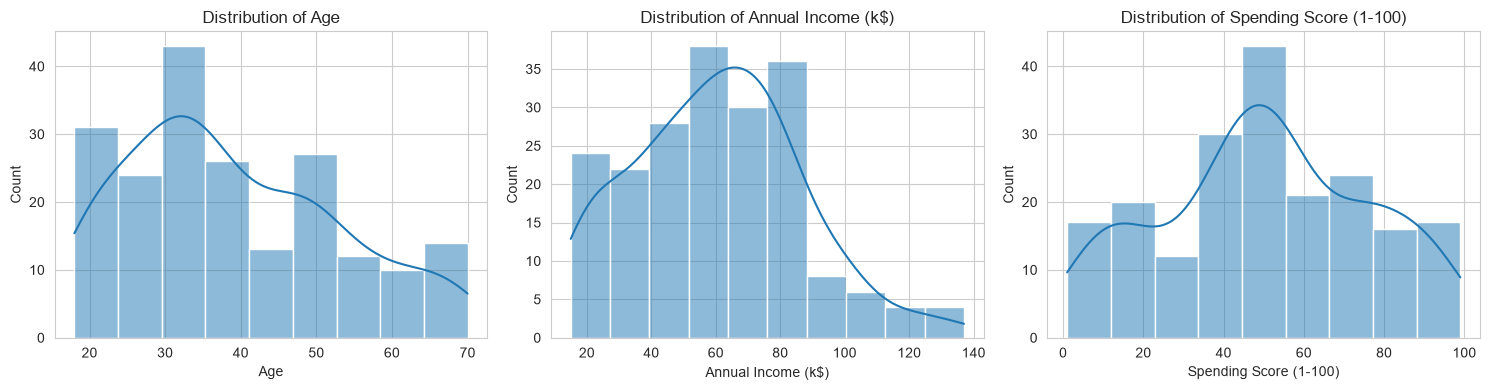

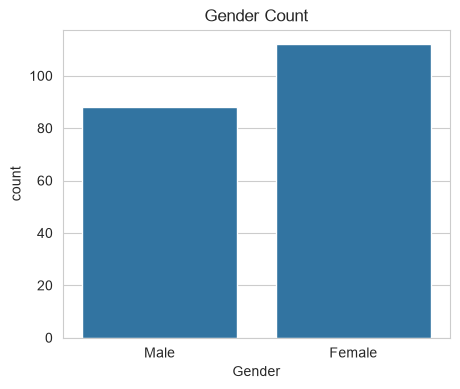

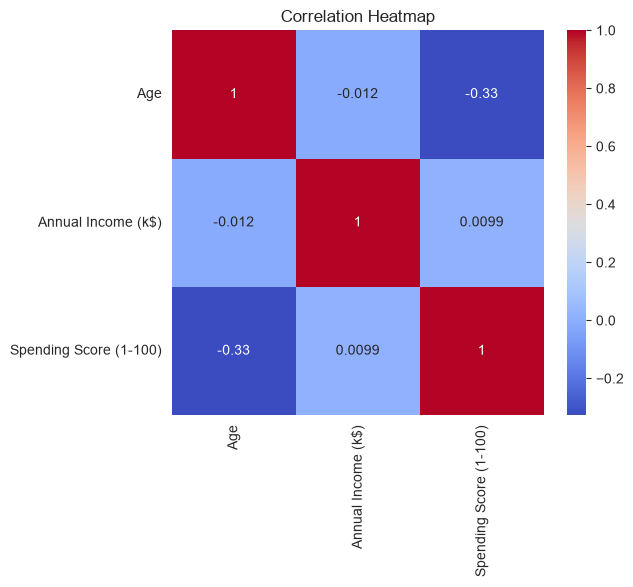

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("outputs/01_distributions.png", dpi=150)
plt.show()

plt.figure(figsize=(5, 4))
sns.countplot(x="Gender", data=df)
plt.title("Gender Count")
plt.savefig("outputs/02_gender_count.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("outputs/03_correlation.png", dpi=150)
plt.show()

## 3. Preprocessing
We cluster on Annual Income and Spending Score, then scale them.

In [14]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(df[features])

## 4. Dendrogram - choosing the number of clusters

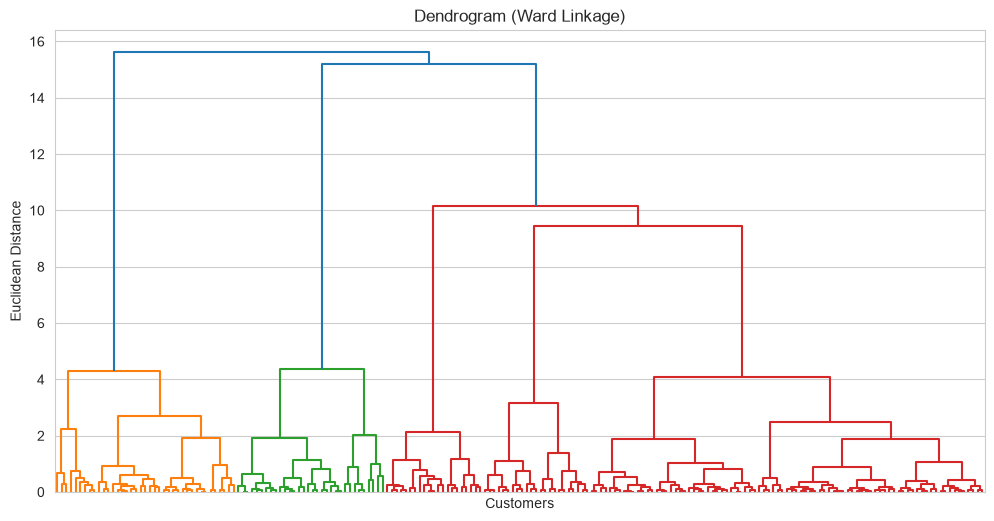

In [15]:
plt.figure(figsize=(12, 6))
sch.dendrogram(sch.linkage(X, method="ward"), no_labels=True)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.savefig("outputs/04_dendrogram.png", dpi=150)
plt.show()

## 5. Compare linkage methods and cluster counts

Linkage   average  complete  single   ward
Clusters                                  
2           0.384     0.361   0.434  0.384
3           0.467     0.467   0.361  0.461
4           0.496     0.496   0.304  0.493
5           0.479     0.553   0.276  0.554
6           0.465     0.544   0.280  0.539
7           0.539     0.531   0.268  0.520
8           0.518     0.508   0.236  0.431


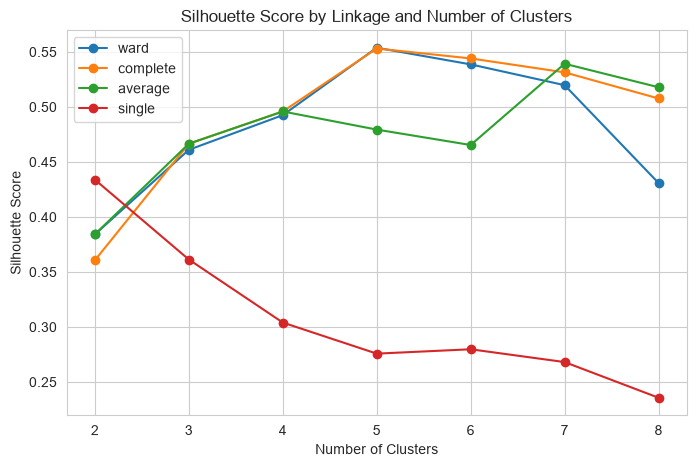


Best: linkage=ward, clusters=5, silhouette=0.554


In [16]:
results = []
for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        results.append({"Linkage": link, "Clusters": k,
                        "Silhouette": silhouette_score(X, labels)})
res_df = pd.DataFrame(results)
print(res_df.pivot(index="Clusters", columns="Linkage", values="Silhouette").round(3))

plt.figure(figsize=(8, 5))
for link in res_df["Linkage"].unique():
    sub = res_df[res_df["Linkage"] == link]
    plt.plot(sub["Clusters"], sub["Silhouette"], marker="o", label=link)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Linkage and Number of Clusters")
plt.legend()
plt.savefig("outputs/05_linkage_comparison.png", dpi=150)
plt.show()

best = res_df.loc[res_df["Silhouette"].idxmax()]
print(f"\nBest: linkage={best['Linkage']}, clusters={int(best['Clusters'])}, "
      f"silhouette={best['Silhouette']:.3f}")

## 6. Final model (Ward linkage, 5 clusters from the dendrogram)

In [17]:
N_CLUSTERS = 5
hc = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
df["Cluster"] = hc.fit_predict(X)

print("Silhouette Score    :", round(silhouette_score(X, df["Cluster"]), 3))
print("Davies-Bouldin Index:", round(davies_bouldin_score(X, df["Cluster"]), 3), "(lower is better)")
print("Calinski-Harabasz   :", round(calinski_harabasz_score(X, df["Cluster"]), 1), "(higher is better)")

Silhouette Score    : 0.554
Davies-Bouldin Index: 0.578 (lower is better)
Calinski-Harabasz   : 244.4 (higher is better)


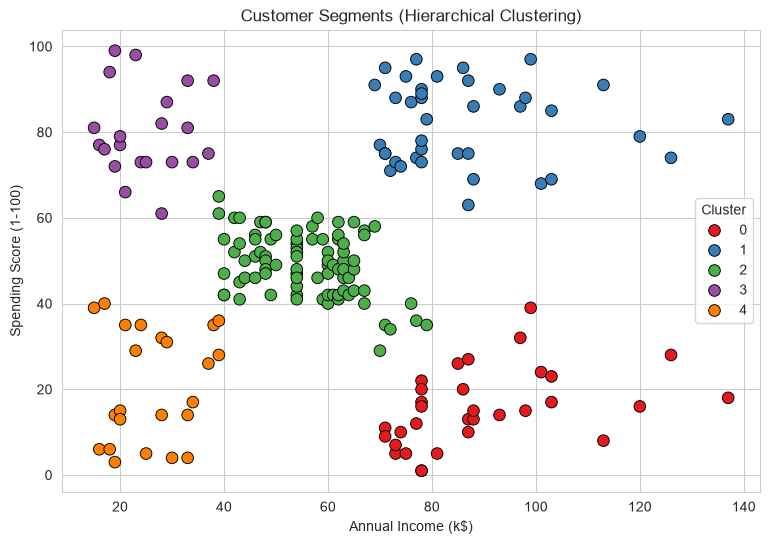

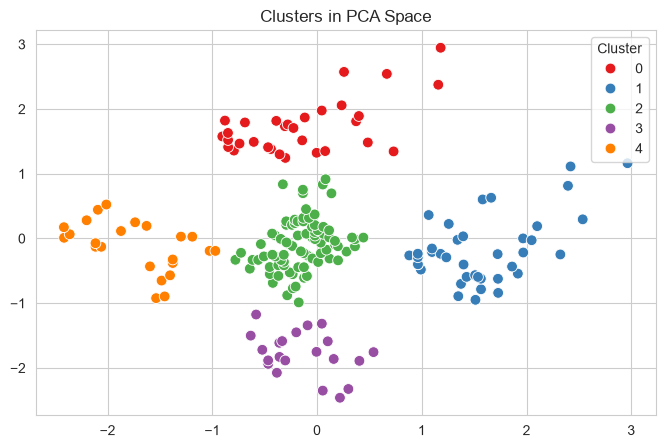

In [18]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=df[features[0]], y=df[features[1]], hue=df["Cluster"],
                palette="Set1", s=70, edgecolor="k")
plt.title("Customer Segments (Hierarchical Clustering)")
plt.savefig("outputs/06_clusters.png", dpi=150)
plt.show()

# PCA view (useful if you later add Age/Gender as features)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Cluster"], palette="Set1", s=60)
plt.title("Clusters in PCA Space")
plt.savefig("outputs/07_pca_clusters.png", dpi=150)
plt.show()

## 7. Cluster profiling

In [19]:
profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Annual Income (k$)", "mean"),
    Avg_Spending=("Spending Score (1-100)", "mean"),
).round(1)

def name_segment(row):
    inc = "High" if row["Avg_Income"] >= 70 else ("Low" if row["Avg_Income"] <= 40 else "Mid")
    spd = "High" if row["Avg_Spending"] >= 60 else ("Low" if row["Avg_Spending"] <= 40 else "Mid")
    names = {
        ("High", "High"): "Premium Customers (Target)",
        ("High", "Low"): "Careful Spenders",
        ("Low", "High"): "Impulsive Spenders",
        ("Low", "Low"): "Budget Customers",
        ("Mid", "Mid"): "Average Customers",
    }
    return names.get((inc, spd), f"{inc} Income / {spd} Spending")

profile["Segment"] = profile.apply(name_segment, axis=1)
print(profile)
profile.to_csv("outputs/cluster_profile.csv")
df.to_csv("outputs/customers_with_clusters.csv", index=False)

         Customers  Avg_Age  Avg_Income  Avg_Spending  \
Cluster                                                 
0               32     41.0        89.4          15.6   
1               39     32.7        86.5          82.1   
2               85     42.5        55.8          49.1   
3               21     25.3        25.1          80.0   
4               23     45.2        26.3          20.9   

                            Segment  
Cluster                              
0                  Careful Spenders  
1        Premium Customers (Target)  
2                 Average Customers  
3                Impulsive Spenders  
4                  Budget Customers  


## 8. Comparison with K-Means

In [20]:
km_labels = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10).fit_predict(X)
comparison = pd.DataFrame({
    "Algorithm": ["Hierarchical (Ward)", "K-Means"],
    "Silhouette": [silhouette_score(X, df["Cluster"]), silhouette_score(X, km_labels)],
    "Davies-Bouldin": [davies_bouldin_score(X, df["Cluster"]), davies_bouldin_score(X, km_labels)],
}).round(3)
print(comparison)

             Algorithm  Silhouette  Davies-Bouldin
0  Hierarchical (Ward)       0.554           0.578
1              K-Means       0.555           0.572


## 9. Marketing recommendations
- **Premium Customers**: loyalty programs, early access to new products.
- **Careful Spenders**: personalised offers and quality-focused promotions.
- **Impulsive Spenders**: limited-time deals, bundles, flash sales.
- **Average Customers**: seasonal discounts to move them upward.
- **Budget Customers**: low-cost promotions, avoid heavy marketing spend.